# Fresh Eyes on CMIP - Aggregating Data Analysis Tools - Introduction

This notebook illustrates how to simply access CMIP data without requiring file downloads. This follows the recent development in CMIP7 of providing [cloud-optimized access to NetCDF](https://wcrp-cmip.github.io/cmip7-guidance/docs/CMIP7/FAQ/#why-is-repacking-necessary).

In [ ]:
import numpy as np
import fsspec
import xarray

## Data search in the ESGF

CMIP7 model output is available through a distributed data archive developed and operated by the Earth System Grid Federation (ESGF). The data are hosted across a network of nodes located at climate modelling centres and data centres around the world.

ESGF is an international collaboration of groups, agencies, and institutions dedicated to developing and operating a long-term system for managing, accessing, and analysing climate data. Its architecture is based on a network of distributed nodes. Data nodes host the available datasets, while index nodes maintain catalogues that allow users to search for data across the network.

Users can connect to any ESGF node through a web browser or a desktop client to search for and access data across the federation. However, individual nodes may occasionally become unavailable, which can temporarily prevent access to some datasets.

There are three options for accessing the data:

1. Metagrid - Metagrid provides a web interface for searching and downloading ESGF data. It is best suited for browsing datasets and downloading a small number of files. Users can search across the distributed archive as though the data were stored in a single central location. Available Metagrid portals:
   - [West index (ORNL)](https://metagrid.esgf-west.org/)
   - [West index (NERSC)](https://metagrid-nersc.west.esgf.io/)
   - [East index](https://metagrid-ceda.east.esgf.io/search)

2. APIs - For larger searches or bulk downloads, automated tools may be more suitable. Several software packages are available for interacting with the ESGF indexes and retrieving data.
   - [ESGpull](https://esgf.github.io/esgf-download/) - Version 0.10.0 supports interaction with the CMIP7 indexes but requires some configuration. Refer to the documentation for setup instructions.
   - [intake-esgf](https://github.com/esgf2-us/intake-esgf) - Version 2026.9.4 supports interaction with the CMIP7 indexes.

In [2]:
UKCM2_0_LL = [
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKCM2-0-LL/historical/r1i1p1f1/glb/mon/tas/tavg-h2m-hxy-u/g110/v20260909/tas_tavg-h2m-hxy-u_mon_glb_g110_UKCM2-0-LL_historical_r1i1p1f1_185001-194912.nc",
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKCM2-0-LL/historical/r1i1p1f1/glb/mon/tas/tavg-h2m-hxy-u/g110/v20260909/tas_tavg-h2m-hxy-u_mon_glb_g110_UKCM2-0-LL_historical_r1i1p1f1_195001-202112.nc",
]

## A very simple climate analysis task



In [7]:
ds = xarray.open_mfdataset(
    [fsspec.open(f, cache_type="first", block_size=2**20).open() for f in UKCM2_0_LL],
    coords="minimal", compat="no_conflicts").chunk({"time": 1032})

ds["tas"]

<xarray.DataArray 'tas' (time: 2064, lat: 144, lon: 192)> Size: 228MB
dask.array<rechunk-merge, shape=(2064, 144, 192), dtype=float32, chunksize=(1032, 144, 192), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 17kB 1850-01-16T12:00:00 ... 2021-12-16T12...
  * lat      (lat) float64 1kB -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
    height   float64 8B 1.5
Attributes:
    standard_name:  air_temperature
    long_name:      Near-Surface Air Temperature
    units:          K
    original_name:  mo: (stash: m01s03i236, lbproc: 128)
    cell_methods:   area: time: mean
    history:        2026-09-03T09:33:42Z altered by CMOR: Treated scalar dime...
    cell_measures:  area: areacella

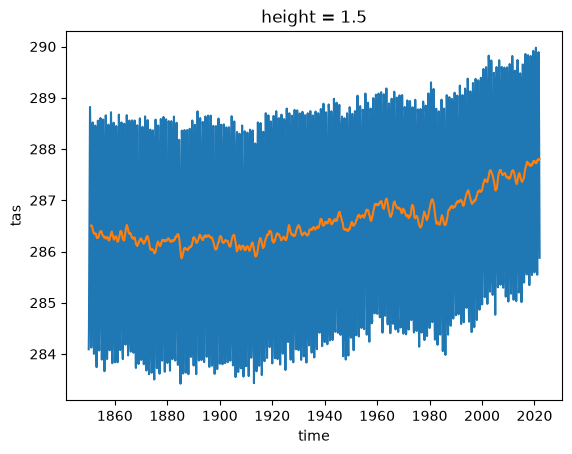

In [8]:
weights = np.cos(np.deg2rad(ds.lat))

ds["tas"].weighted(weights).mean(["lat", "lon"]).plot(label="monthly")
ds["tas"].weighted(weights).mean(["lat", "lon"]).rolling(time=12).mean().plot(label="12 month rolling mean")